# Experiment 6: K-Means Clustering & Finding Optimal K

**Objective:**
1. Generate synthetic data with 4 natural clusters.
2. Determine optimal $K$ using the Elbow Method (WCSS / Inertia).
3. Evaluate cluster quality using Silhouette Scores across multiple $K$ values.
4. Fit the final K-Means model with optimal $K = 4$ and visualize clusters with centroids.

### Step 1: Import Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

### Step 2: Generate Synthetic Dataset

In [2]:
# Generate 300 points in 4 distinct clusters
X, y = make_blobs(
    n_samples=300, centers=4, cluster_std=1.0, random_state=42
)

print(f"Dataset generated: {X.shape[0]} points, {X.shape[1]} features")

Dataset generated: 300 points, 2 features


### Step 3: Determine Optimal K using the Elbow Method

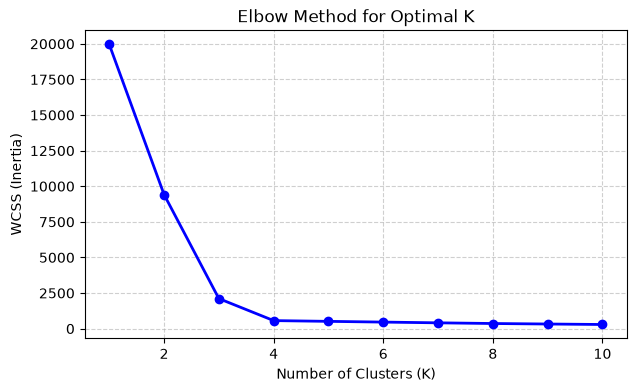

In [3]:
# Calculate Within-Cluster Sum of Squares (WCSS) for K = 1 to 10
wcss = []
k_range = range(1, 11)

for k in k_range:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X)
    wcss.append(model.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(7, 4))
plt.plot(k_range, wcss, marker='o', color='b', linewidth=2)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.title("Elbow Method for Optimal K")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Step 4: Evaluate Cluster Quality using Silhouette Scores

In [4]:
# Evaluate Silhouette Score for K = 2 to 10
records = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = model.fit_predict(X)
    score = silhouette_score(X, cluster_labels)
    records.append({'K': k, 'WCSS': round(model.inertia_, 2), 'Silhouette Score': round(score, 4)})

summary_df = pd.DataFrame(records)
print("=== K Evaluation Metrics ===")
print(summary_df.to_string(index=False))
print("\nNotice: Highest Silhouette Score occurs at K = 4!")

=== K Evaluation Metrics ===
 K    WCSS  Silhouette Score
 2 9416.21            0.5902
 3 2110.41            0.7569
 4  564.91            0.7916
 5  512.39            0.6890
 6  460.31            0.5514
 7  408.95            0.4297
 8  360.82            0.3369
 9  325.37            0.3502
10  291.56            0.3617

Notice: Highest Silhouette Score occurs at K = 4!


### Step 5: Fit Final Model (K = 4) and Plot Clusters with Centroids

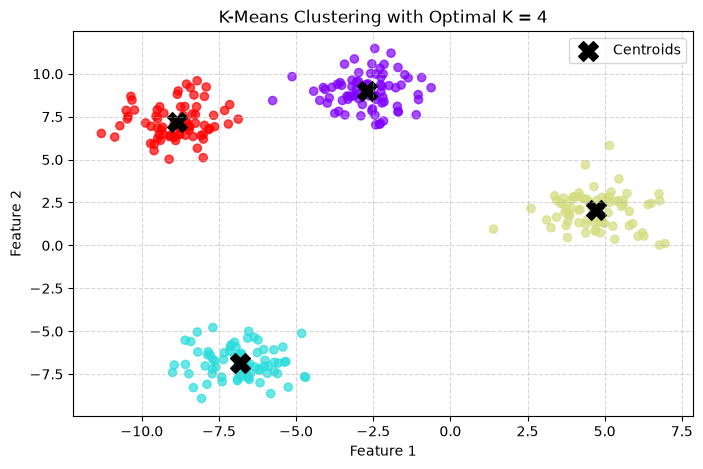

In [5]:
# Fit final model with optimal K=4
optimal_k = 4
final_model = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
final_labels = final_model.fit_predict(X)

# Scatter plot of clusters
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], c=final_labels, cmap='rainbow', s=35, alpha=0.7)

# Overlay cluster centroids marked with black 'X'
centroids = final_model.cluster_centers_
plt.scatter(
    centroids[:, 0], centroids[:, 1],
    color='black', marker='X', s=200, label='Centroids'
)

plt.title(f"K-Means Clustering with Optimal K = {optimal_k}")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()